In [2]:
pip install wfdb numpy scipy matplotlib scikit-learn torch

In [3]:
import os, random, copy
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import torch
import torch.nn as nn
from scipy.signal import butter, filtfilt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

# Config
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "mitdb"
FS = 360                       # sampling rate (Hz)
PRE, POST = 90, 90             # samples before / after R-peak -> 180-sample window
CLASSES = ["N", "S", "V", "F", "Q"]

# AAMI mapping of MIT-BIH beat symbols (any other symbol = non-beat -> removed)
AAMI = {"N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
        "A": "S", "a": "S", "J": "S", "S": "S",
        "V": "V", "E": "V",
        "F": "F",
        "/": "Q", "f": "Q", "Q": "Q"}

# Inter-patient split (de Chazal DS1 / DS2). Paced records 102,104,107,217 are removed.
PACED = ["102", "104", "107", "217"]
DS1 = ["101", "106", "108", "109", "112", "114", "115", "116", "118", "119", "122",
       "124", "201", "203", "205", "207", "208", "209", "215", "220", "223", "230"]
DS2 = ["100", "103", "105", "111", "113", "117", "121", "123", "200", "202", "210",
       "212", "213", "214", "219", "221", "222", "228", "231", "232", "233", "234"]
VAL_RECORDS = ["106", "112", "201", "209"]            # held out of DS1 for validation
TRAIN_RECORDS = [r for r in DS1 if r not in VAL_RECORDS]
TEST_RECORDS = DS2
ALL_RECORDS = DS1 + DS2 + PACED                       # all 48 records

HIDDEN, BATCH, LR, MAX_EPOCHS, PATIENCE = 64, 256, 1e-3, 30, 5

# Task 1: Data acquisition and exploration

## Task 1: Data Acquisition and Exploration
### Data acquisition (PhysioNet, wfdb)

In [4]:
if not os.path.isdir(DATA_DIR):
    wfdb.dl_database("mitdb", DATA_DIR, records=ALL_RECORDS)

def load_record(rec):
    record = wfdb.rdrecord(f"{DATA_DIR}/{rec}")
    ann = wfdb.rdann(f"{DATA_DIR}/{rec}", "atr")
    ch = record.sig_name.index("MLII") if "MLII" in record.sig_name else 0
    return record.p_signal[:, ch], ann

# Task 2: Preprocessing

Generating record list for: 101
Generating record list for: 106
Generating record list for: 108
Generating record list for: 109
Generating record list for: 112
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 118
Generating record list for: 119
Generating record list for: 122
Generating record list for: 124
Generating record list for: 201
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generating record list for: 215
Generating record list for: 220
Generating record list for: 223
Generating record list for: 230
Generating record list for: 100
Generating record list for: 103
Generating record list for: 105
Generating record list for: 111
Generating record list for: 113
Generating record list for: 117
Generating record list for: 121
Generating record list for: 123
Generating record list for: 200
Generati

## Task 2: Data Preprocessing
### Noise removal, segmentation, feature extraction (beat + RR) and normalization

In [5]:
_b, _a = butter(3, [0.5, 40], btype="band", fs=FS)

def bandpass(sig):
    """0.5-40 Hz zero-phase bandpass: removes baseline wander and high-frequency noise."""
    return filtfilt(_b, _a, sig)

def segment(sig, ann):
    """Fixed-length window around each R-peak + label + RR intervals; per-beat z-score."""
    keep = [(s, AAMI[sym]) for s, sym in zip(ann.sample, ann.symbol) if sym in AAMI]
    peaks = np.array([k[0] for k in keep])
    X, RR, y = [], [], []
    for i, (p, lab) in enumerate(keep):
        if i == 0 or i == len(keep) - 1 or p - PRE < 0 or p + POST > len(sig):
            continue
        w = sig[p - PRE:p + POST]
        X.append((w - w.mean()) / (w.std() + 1e-8))                       # normalization
        RR.append([(p - peaks[i - 1]) / FS, (peaks[i + 1] - p) / FS])      # pre-/post-RR (s)
        y.append(CLASSES.index(lab))
    return np.array(X, np.float32), np.array(RR, np.float32), np.array(y, np.int64)

### Signal inspection (raw vs filtered)

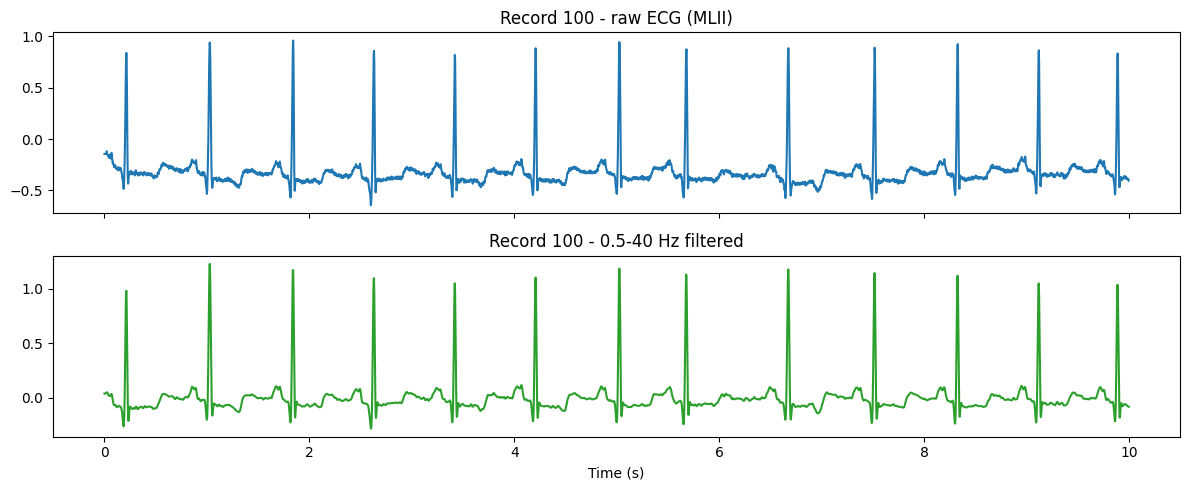

In [6]:
# Signal inspection: raw vs filtered (record 100, first 10 s)
raw, ann100 = load_record("100")
seg = slice(0, 10 * FS)
t = np.arange(seg.stop) / FS
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(t, raw[seg]); ax[0].set_title("Record 100 - raw ECG (MLII)")
ax[1].plot(t, bandpass(raw)[seg], color="tab:green"); ax[1].set_title("Record 100 - 0.5-40 Hz filtered")
ax[1].set_xlabel("Time (s)"); plt.tight_layout(); plt.show()

### Cleaning (paced records / non-beat annotations removed) and inter-patient split

In [7]:
# Build beat dataset (paced records skipped, non-beat annotations dropped inside segment())
data = {}
for rec in ALL_RECORDS:
    if rec in PACED:
        continue
    sig, ann = load_record(rec)
    data[rec] = segment(bandpass(sig), ann)

def gather(records):
    return (np.concatenate([data[r][0] for r in records])[..., None],
            np.concatenate([data[r][1] for r in records]),
            np.concatenate([data[r][2] for r in records]))

X_tr, RR_tr, y_tr = gather(TRAIN_RECORDS)
X_va, RR_va, y_va = gather(VAL_RECORDS)
X_te, RR_te, y_te = gather(TEST_RECORDS)

### Class distribution and class-imbalance handling

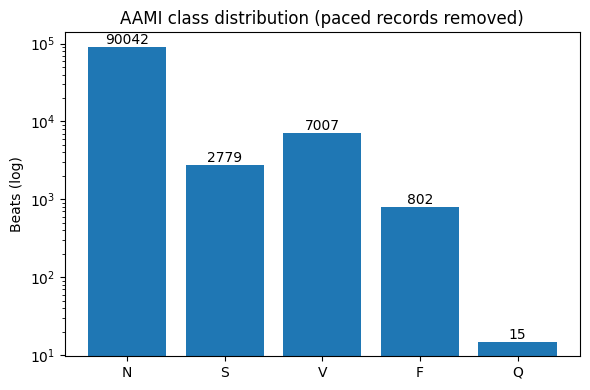

Class counts: {'N': np.int64(90042), 'S': np.int64(2779), 'V': np.int64(7007), 'F': np.int64(802), 'Q': np.int64(15)}
Train 41451 | Val 9526 | Test 49668


In [8]:
# Class distribution (all cleaned beats)
y_all = np.concatenate([data[r][2] for r in data])
counts = np.bincount(y_all, minlength=5)
plt.figure(figsize=(6, 4)); plt.bar(CLASSES, counts, color="tab:blue")
for i, c in enumerate(counts): plt.text(i, c, str(c), ha="center", va="bottom")
plt.yscale("log"); plt.title("AAMI class distribution (paced records removed)"); plt.ylabel("Beats (log)")
plt.tight_layout(); plt.show()
print("Class counts:", dict(zip(CLASSES, counts)))
print(f"Train {len(y_tr)} | Val {len(y_va)} | Test {len(y_te)}")

# Class imbalance: inverse-frequency class weights in the loss (computed on train set only)
tr_counts = np.maximum(np.bincount(y_tr, minlength=5), 1)
class_w = torch.tensor(len(y_tr) / (5 * tr_counts), dtype=torch.float32, device=DEVICE)

# Task 3: Models, training, evaluation

## Task 3: Model Training and Evaluation
### Model design (RNN / LSTM / GRU)

In [9]:
class BeatClassifier(nn.Module):
    """Identical architecture; only the recurrent cell changes."""
    def __init__(self, kind):
        super().__init__()
        cell = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = cell(1, HIDDEN, batch_first=True)
        self.head = nn.Sequential(nn.Linear(HIDDEN + 2, 64), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(64, len(CLASSES)))
    def forward(self, x, rr):
        out, _ = self.rnn(x)
        return self.head(torch.cat([out[:, -1], rr], dim=1))

### Training and validation (identical settings, early stopping)

In [10]:
def to_loader(X, RR, y, shuffle):
    ds = torch.utils.data.TensorDataset(torch.from_numpy(X), torch.from_numpy(RR), torch.from_numpy(y))
    return torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader = to_loader(X_tr, RR_tr, y_tr, True)
val_loader = to_loader(X_va, RR_va, y_va, False)
test_loader = to_loader(X_te, RR_te, y_te, False)

def run_epoch(model, loader, loss_fn, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total, preds, trues = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, rr, y in loader:
            x, rr, y = x.to(DEVICE), rr.to(DEVICE), y.to(DEVICE)
            logits = model(x, rr)
            loss = loss_fn(logits, y)
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total += loss.item() * len(y)
            preds.append(logits.argmax(1).cpu().numpy()); trues.append(y.cpu().numpy())
    return total / len(loader.dataset), np.concatenate(preds), np.concatenate(trues)

def train_model(kind):
    torch.manual_seed(SEED)
    model = BeatClassifier(kind).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=class_w)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    best_loss, best_state, wait = float("inf"), None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, _, _ = run_epoch(model, train_loader, loss_fn, opt)
        va_loss, va_pred, va_true = run_epoch(model, val_loader, loss_fn)
        print(f"[{kind}] epoch {epoch:02d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} "
              f"| val acc {accuracy_score(va_true, va_pred):.4f}")
        if va_loss < best_loss:
            best_loss, best_state, wait = va_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"[{kind}] early stopping at epoch {epoch}"); break
    model.load_state_dict(best_state)
    return model

### Testing and performance comparison

In [11]:
results, cms = {}, {}
for kind in ["RNN", "LSTM", "GRU"]:
    model = train_model(kind)
    _, pred, true = run_epoch(model, test_loader, nn.CrossEntropyLoss(weight=class_w))
    print(f"\n===== {kind} - test set =====")
    print(classification_report(true, pred, labels=range(5), target_names=CLASSES, zero_division=0))
    p, r, f, _ = precision_recall_fscore_support(true, pred, average="macro", zero_division=0)
    results[kind] = dict(Accuracy=accuracy_score(true, pred), Precision=p, Recall=r, F1=f)
    cms[kind] = confusion_matrix(true, pred, labels=range(5))

# Performance comparison
print("\n===== Test-set comparison (macro-averaged P/R/F1) =====")
print(f"{'Model':<6}{'Accuracy':>10}{'Precision':>11}{'Recall':>9}{'F1':>8}")
for k, m in results.items():
    print(f"{k:<6}{m['Accuracy']:>10.4f}{m['Precision']:>11.4f}{m['Recall']:>9.4f}{m['F1']:>8.4f}")

[RNN] epoch 01 | train loss 1.4437 | val loss 1.5102 | val acc 0.6331
[RNN] epoch 02 | train loss 1.3089 | val loss 1.6877 | val acc 0.3640
[RNN] epoch 03 | train loss 1.2938 | val loss 1.9622 | val acc 0.1154
[RNN] epoch 04 | train loss 1.2805 | val loss 1.6182 | val acc 0.2059
[RNN] epoch 05 | train loss 1.2364 | val loss 1.8997 | val acc 0.2324
[RNN] epoch 06 | train loss 1.1841 | val loss 1.8465 | val acc 0.2727
[RNN] early stopping at epoch 6

===== RNN - test set =====
              precision    recall  f1-score   support

           N       0.90      0.84      0.87     44218
           S       0.01      0.00      0.01      1836
           V       0.14      0.21      0.17      3219
           F       0.01      0.05      0.01       388
           Q       0.00      0.00      0.00         7

    accuracy                           0.77     49668
   macro avg       0.21      0.22      0.21     49668
weighted avg       0.81      0.77      0.79     49668

[LSTM] epoch 01 | train loss 1.

### Confusion matrices

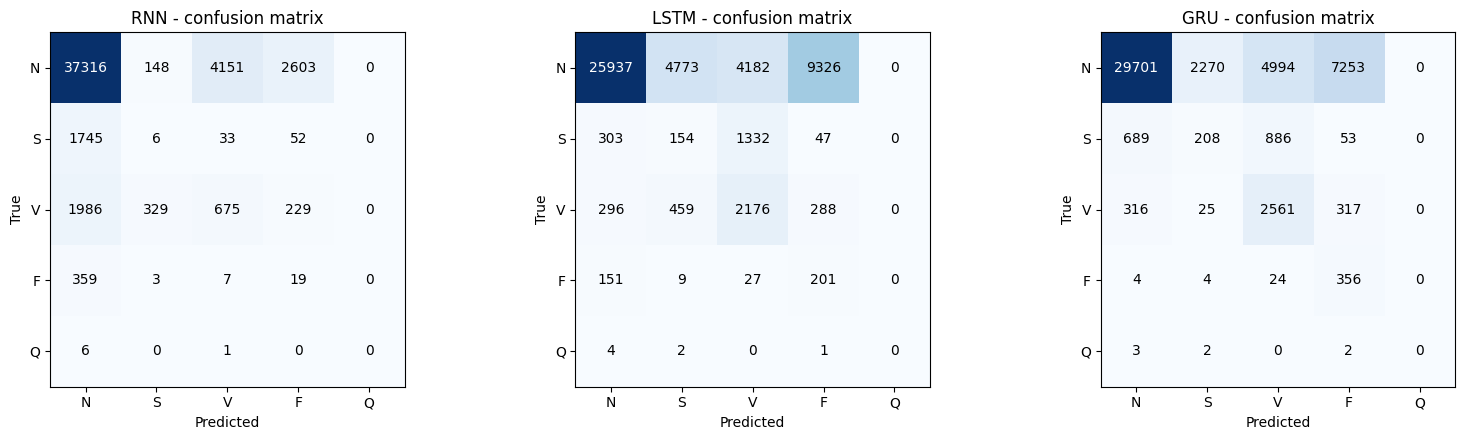

In [12]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (k, cm) in zip(axes, cms.items()):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"{k} - confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_xticks(range(5)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(5)); ax.set_yticklabels(CLASSES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()